# imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load Dataset

In [2]:
DATA_PATH = "../data/processed/CIB_features.csv"

df = pd.read_csv(DATA_PATH)

df["Date"] = pd.to_datetime(df["Date"])

df = df.sort_values("Date").reset_index(drop=True)

df.head()

,Date,Close,Open,High,Low,Volume,Change %,Return_1d,Return_3d,Return_5d,...,High_Low_Range,Open_Close_Range,Volume_Change,Volume_SMA_10,Close_lag_1,Close_lag_2,Close_lag_3,Close_lag_5,Close_lag_10,Target
0,2021-09-01,1.855,1.855,1.862,1.771,65200.0,3.02,NaN,NaN,NaN,...,0.049057,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.849
1,2021-09-02,1.849,1.849,1.849,1.801,177910.0,-0.33,-0.003235,NaN,NaN,...,0.025960,0.000000,1.728681,NaN,1.855,NaN,NaN,NaN,NaN,1.843
2,2021-09-03,1.843,1.836,1.843,1.775,69020.0,-0.33,-0.003245,NaN,NaN,...,0.036896,0.003813,-0.612051,NaN,1.849,1.855,NaN,NaN,NaN,1.795
3,2021-09-07,1.795,1.749,1.801,1.749,83090.0,-2.62,-0.026044,-0.032345,NaN,...,0.028969,0.026301,0.203854,NaN,1.843,1.849,1.855,NaN,NaN,1.819
4,2021-09-08,1.819,1.801,1.819,1.777,29790.0,1.35,0.013370,-0.016225,NaN,...,0.023090,0.009994,-0.641473,NaN,1.795,1.843,1.849,NaN,NaN,1.795


In [3]:
print("Shape:", df.shape)
print("Date range:", df["Date"].min(), "→", df["Date"].max())

Shape: (1265, 34)
Date range: 2021-09-01 00:00:00 → 2026-09-30 00:00:00


In [4]:
df.columns.tolist()

['Date',
 'Close',
 'Open',
 'High',
 'Low',
 'Volume',
 'Change %',
 'Return_1d',
 'Return_3d',
 'Return_5d',
 'Return_10d',
 'SMA_10',
 'SMA_20',
 'EMA_10',
 'EMA_20',
 'RSI_14',
 'MACD',
 'MACD_Signal',
 'MACD_Hist',
 'BB_Upper',
 'BB_Lower',
 'BB_Width',
 'Volatility_10',
 'Volatility_20',
 'High_Low_Range',
 'Open_Close_Range',
 'Volume_Change',
 'Volume_SMA_10',
 'Close_lag_1',
 'Close_lag_2',
 'Close_lag_3',
 'Close_lag_5',
 'Close_lag_10',
 'Target']

In [5]:
df.dtypes

Date                datetime64[ns]
Close                      float64
Open                       float64
High                       float64
Low                        float64
Volume                     float64
Change %                   float64
Return_1d                  float64
Return_3d                  float64
Return_5d                  float64
Return_10d                 float64
SMA_10                     float64
SMA_20                     float64
EMA_10                     float64
EMA_20                     float64
RSI_14                     float64
MACD                       float64
MACD_Signal                float64
MACD_Hist                  float64
BB_Upper                   float64
BB_Lower                   float64
BB_Width                   float64
Volatility_10              float64
Volatility_20              float64
High_Low_Range             float64
Open_Close_Range           float64
Volume_Change              float64
Volume_SMA_10              float64
Close_lag_1         

# 1- price analysis

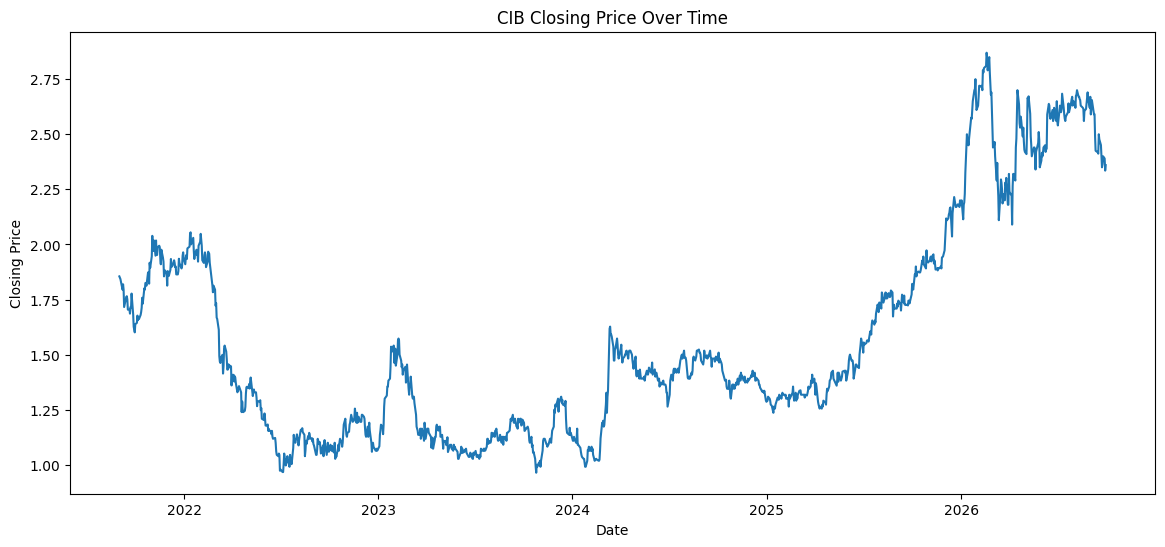

In [6]:
plt.figure(figsize=(14, 6))

plt.plot(df["Date"], df["Close"])

plt.title("CIB Closing Price Over Time")
plt.xlabel("Date")
plt.ylabel("Closing Price")

plt.show()

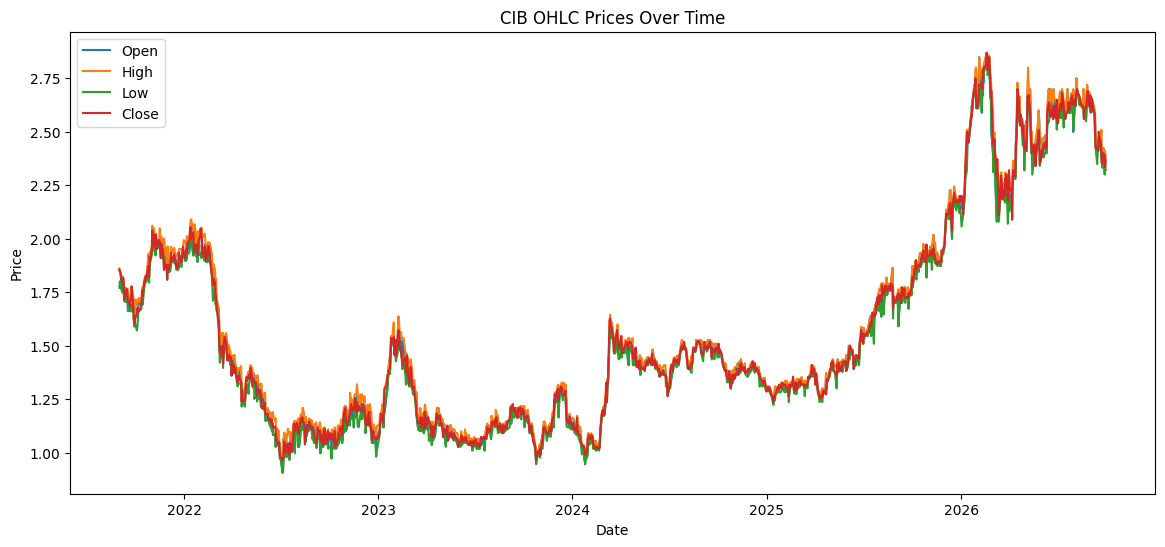

In [7]:
plt.figure(figsize=(14, 6))

plt.plot(df["Date"], df["Open"], label="Open")
plt.plot(df["Date"], df["High"], label="High")
plt.plot(df["Date"], df["Low"], label="Low")
plt.plot(df["Date"], df["Close"], label="Close")

plt.title("CIB OHLC Prices Over Time")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()

plt.show()

In [8]:
df[["Open", "High", "Low", "Close"]].describe()

,Open,High,Low,Close
count,1265.000000,1265.000000,1265.000000,1265.000000
mean,1.564111,1.590022,1.537816,1.562326
std,0.487289,0.488124,0.481255,0.484142
min,0.906000,0.973000,0.906000,0.964000
25%,1.173000,1.200000,1.136000,1.168000
50%,1.409000,1.427000,1.391000,1.401000
75%,1.873000,1.891000,1.843000,1.864000
max,2.860000,2.870000,2.810000,2.870000


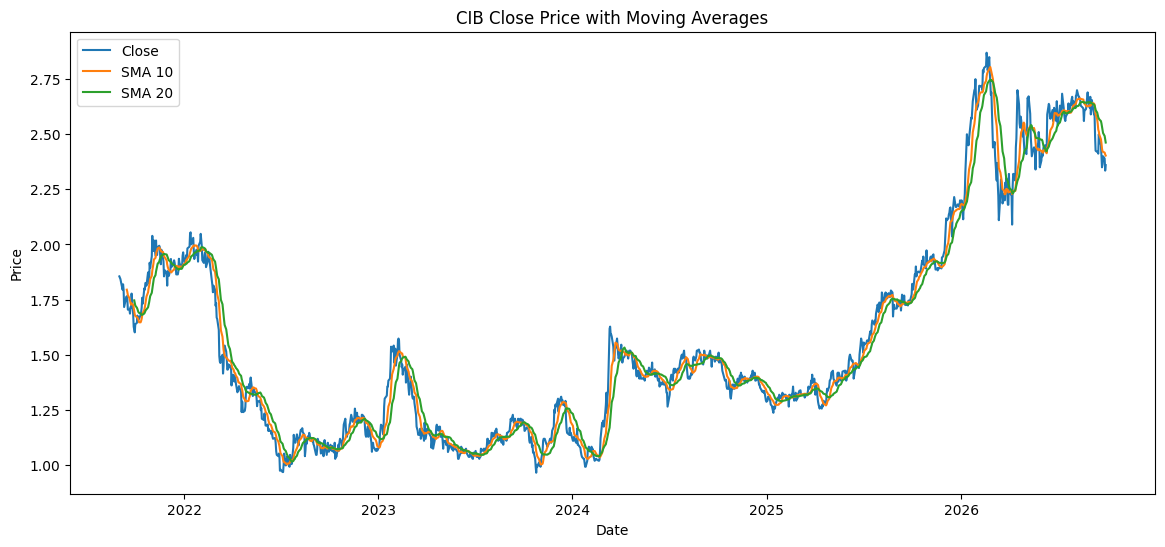

In [9]:
plt.figure(figsize=(14, 6))

plt.plot(df["Date"], df["Close"], label="Close")
plt.plot(df["Date"], df["SMA_10"], label="SMA 10")
plt.plot(df["Date"], df["SMA_20"], label="SMA 20")

plt.title("CIB Close Price with Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()

plt.show()

In [10]:
highest = df.loc[df["Close"].idxmax()]
lowest = df.loc[df["Close"].idxmin()]

print("Highest Close:")
print(highest[["Date", "Close"]])

print("\nLowest Close:")
print(lowest[["Date", "Close"]])

Highest Close:
Date     2026-02-18 00:00:00
Close                   2.87
Name: 1111, dtype: object

Lowest Close:
Date     2023-10-25 00:00:00
Close                  0.964
Name: 540, dtype: object


# 2-Return Analysis

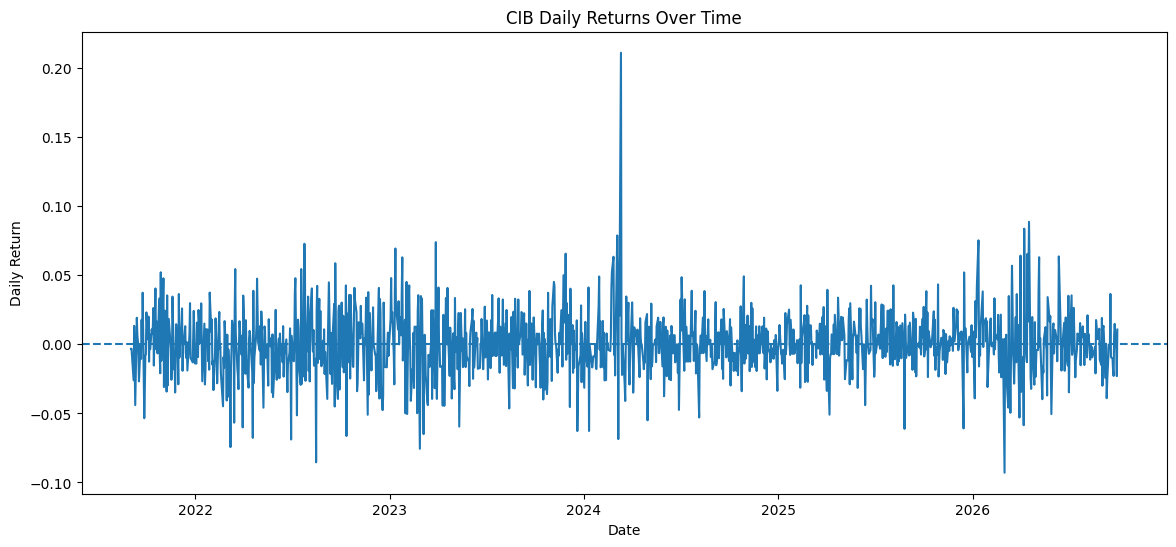

In [11]:
plt.figure(figsize=(14, 6))

plt.plot(df["Date"], df["Return_1d"])

plt.axhline(0, linestyle="--")

plt.title("CIB Daily Returns Over Time")
plt.xlabel("Date")
plt.ylabel("Daily Return")

plt.show()

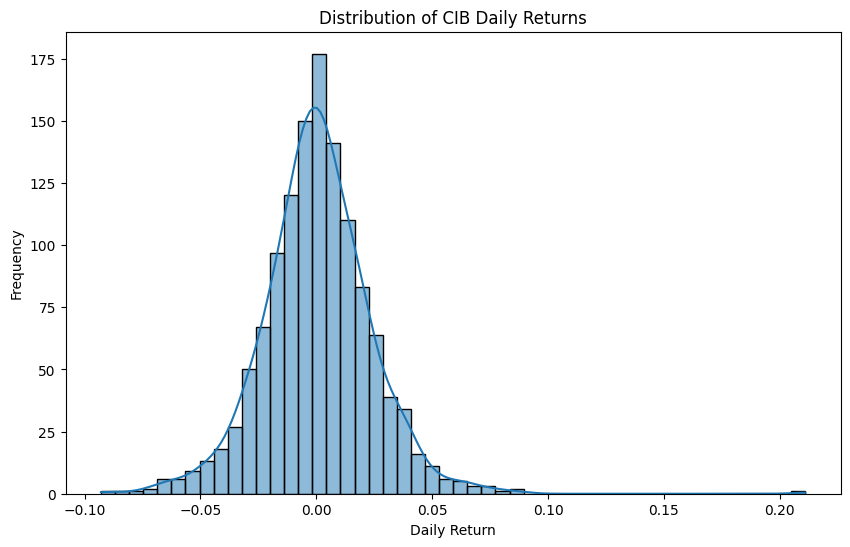

In [12]:
plt.figure(figsize=(10, 6))

sns.histplot(df["Return_1d"].dropna(), bins=50, kde=True)

plt.title("Distribution of CIB Daily Returns")
plt.xlabel("Daily Return")
plt.ylabel("Frequency")

plt.show()

In [13]:
df[["Return_1d", "Return_3d", "Return_5d", "Return_10d"]].describe()

,Return_1d,Return_3d,Return_5d,Return_10d
count,1264.000000,1262.000000,1260.000000,1255.000000
mean,0.000464,0.001283,0.002143,0.004836
std,0.023489,0.037862,0.047867,0.071956
min,-0.092937,-0.116727,-0.153403,-0.215613
25%,-0.012948,-0.020008,-0.026681,-0.037651
50%,0.000000,0.000000,0.000000,0.000000
75%,0.013662,0.019944,0.026164,0.041175
max,0.211078,0.309061,0.287217,0.376481


In [14]:
positive = (df["Return_1d"] > 0).sum()
negative = (df["Return_1d"] < 0).sum()
zero = (df["Return_1d"] == 0).sum()

print("Positive days:", positive)
print("Negative days:", negative)
print("Zero-return days:", zero)

Positive days: 586
Negative days: 576
Zero-return days: 102


In [15]:
total = positive + negative + zero

print("Positive %:", positive / total * 100)
print("Negative %:", negative / total * 100)
print("Zero %:", zero / total * 100)

Positive %: 46.360759493670884
Negative %: 45.56962025316456
Zero %: 8.069620253164556


In [16]:
best_days = df.nlargest(10, "Return_1d")[["Date", "Close", "Return_1d"]]

worst_days = df.nsmallest(10, "Return_1d")[["Date", "Close", "Return_1d"]]

print("Best 10 Days:")
display(best_days)

print("\nWorst 10 Days:")
display(worst_days)

Best 10 Days:


,Date,Close,Return_1d
633,2024-03-11,1.618,0.211078
1151,2026-04-17,2.700,0.088710
1145,2026-04-08,2.265,0.083732
628,2024-03-04,1.273,0.078814
1086,2026-01-12,2.500,0.075269
395,2023-03-29,1.191,0.073940
224,2022-07-25,1.076,0.072782
343,2023-01-12,1.264,0.069374
563,2023-11-28,1.250,0.065644
1149,2026-04-14,2.440,0.065502



Worst 10 Days:


,Date,Close,Return_1d
1119,2026-03-02,2.440,-0.092937
240,2022-08-16,1.039,-0.085387
373,2023-02-27,1.345,-0.075601
129,2022-03-08,1.493,-0.074396
208,2022-06-30,0.973,-0.068900
630,2024-03-06,1.236,-0.068576
158,2022-04-19,1.239,-0.067720
280,2022-10-12,1.027,-0.066364
378,2023-03-06,1.309,-0.065000
579,2023-12-20,1.209,-0.062791


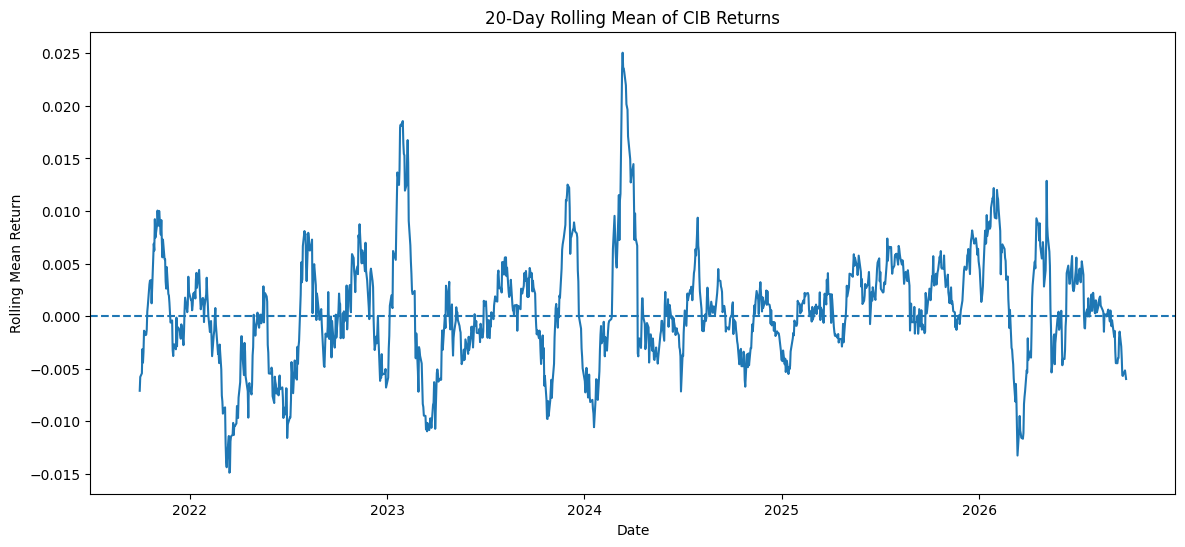

In [17]:
df["Return_1d_Rolling_Mean_20"] = (
    df["Return_1d"].rolling(20).mean()
)

plt.figure(figsize=(14, 6))

plt.plot(df["Date"], df["Return_1d_Rolling_Mean_20"])

plt.axhline(0, linestyle="--")

plt.title("20-Day Rolling Mean of CIB Returns")
plt.xlabel("Date")
plt.ylabel("Rolling Mean Return")

plt.show()

# 3-Volatility Analsysis

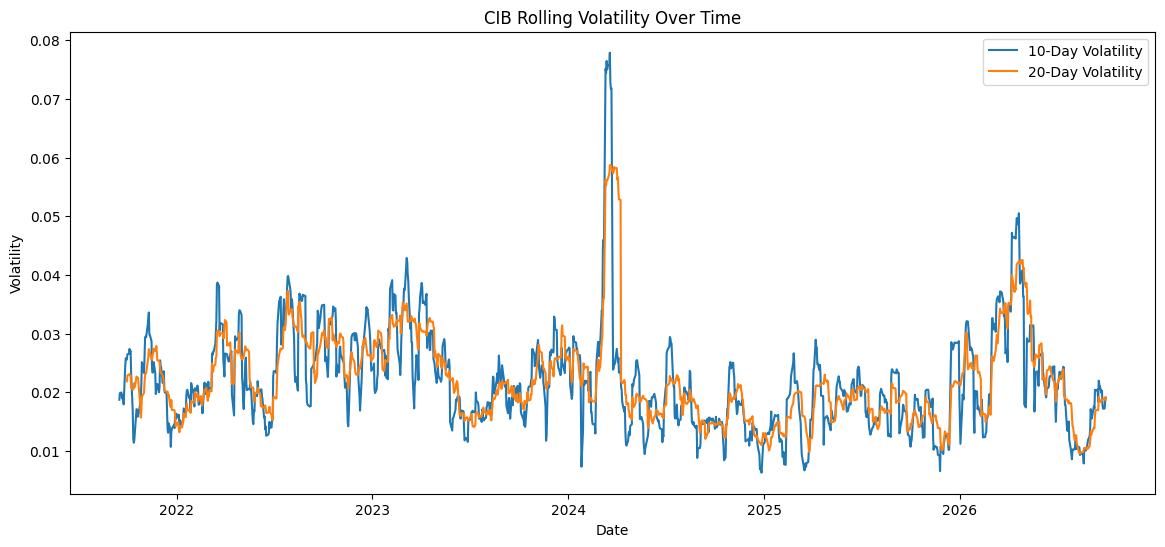

In [18]:
plt.figure(figsize=(14, 6))

plt.plot(df["Date"], df["Volatility_10"], label="10-Day Volatility")
plt.plot(df["Date"], df["Volatility_20"], label="20-Day Volatility")

plt.title("CIB Rolling Volatility Over Time")
plt.xlabel("Date")
plt.ylabel("Volatility")
plt.legend()

plt.show()

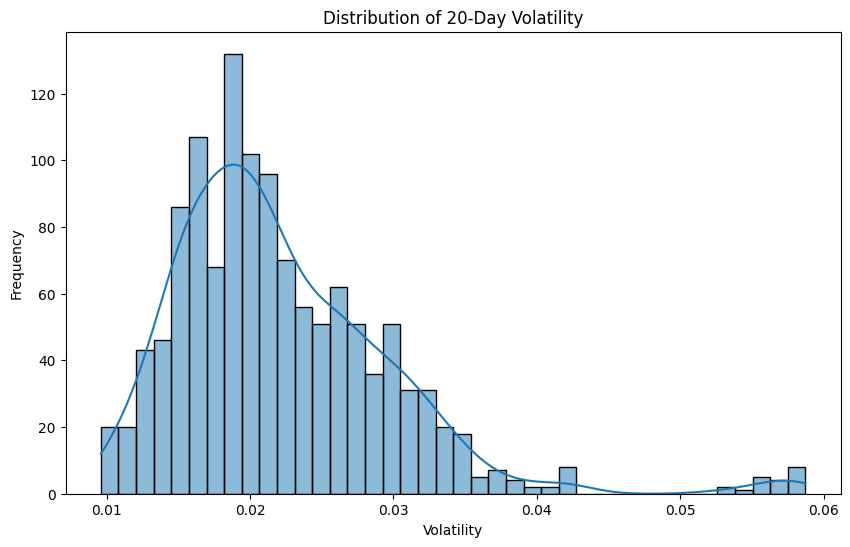

In [19]:
plt.figure(figsize=(10, 6))

sns.histplot(df["Volatility_20"].dropna(), bins=40, kde=True)

plt.title("Distribution of 20-Day Volatility")
plt.xlabel("Volatility")
plt.ylabel("Frequency")

plt.show()

In [20]:
df[["Volatility_10", "Volatility_20"]].describe()

,Volatility_10,Volatility_20
count,1255.000000,1245.000000
mean,0.021876,0.022207
std,0.008944,0.007730
min,0.006307,0.009587
25%,0.015654,0.016873
50%,0.020467,0.020641
75%,0.026275,0.026130
max,0.077863,0.058738


In [21]:
high_vol = df.nlargest(
    10, "Volatility_20"
)[["Date", "Close", "Volatility_20"]]

display(high_vol)

,Date,Close,Volatility_20
640,2024-03-20,1.473,0.058738
639,2024-03-19,1.473,0.058661
641,2024-03-21,1.524,0.058652
645,2024-03-27,1.500,0.058419
642,2024-03-22,1.527,0.058245
647,2024-04-01,1.527,0.058228
646,2024-03-28,1.482,0.058133
644,2024-03-26,1.545,0.057583
643,2024-03-25,1.573,0.057322
638,2024-03-18,1.536,0.057216


In [22]:
high_vol = df.nlargest(
    10, "Volatility_20"
)[["Date", "Close", "Volatility_20"]]

display(high_vol)

,Date,Close,Volatility_20
640,2024-03-20,1.473,0.058738
639,2024-03-19,1.473,0.058661
641,2024-03-21,1.524,0.058652
645,2024-03-27,1.500,0.058419
642,2024-03-22,1.527,0.058245
647,2024-04-01,1.527,0.058228
646,2024-03-28,1.482,0.058133
644,2024-03-26,1.545,0.057583
643,2024-03-25,1.573,0.057322
638,2024-03-18,1.536,0.057216


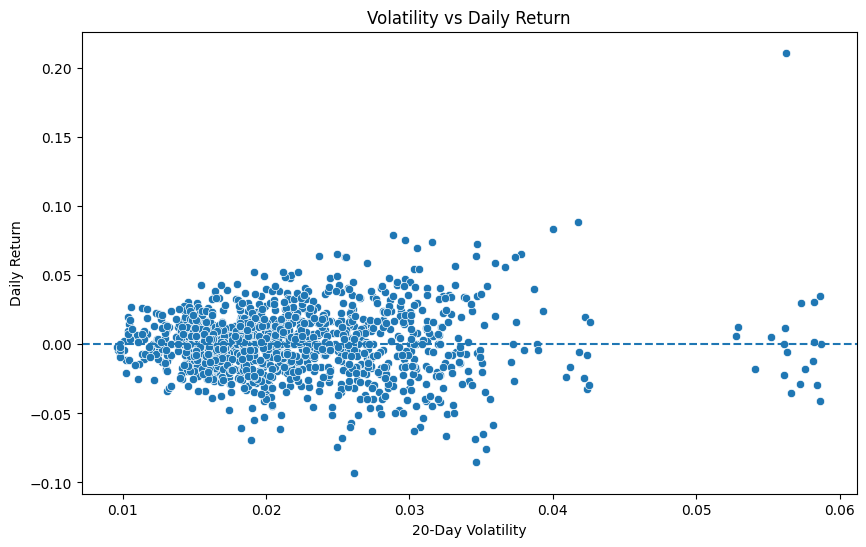

In [23]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Volatility_20",
    y="Return_1d"
)

plt.axhline(0, linestyle="--")

plt.title("Volatility vs Daily Return")
plt.xlabel("20-Day Volatility")
plt.ylabel("Daily Return")

plt.show()

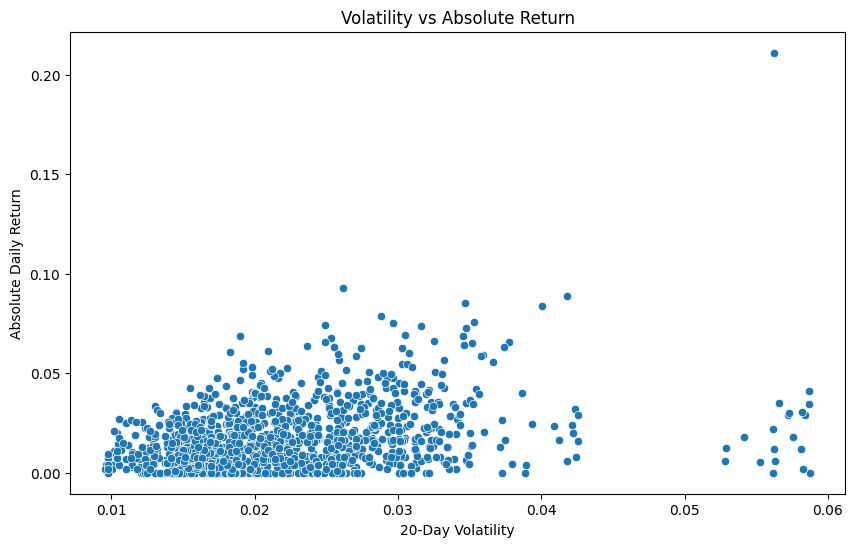

In [24]:
df["Abs_Return"] = df["Return_1d"].abs()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Volatility_20",
    y="Abs_Return"
)

plt.title("Volatility vs Absolute Return")
plt.xlabel("20-Day Volatility")
plt.ylabel("Absolute Daily Return")

plt.show()

# 4-Volumne Analysis

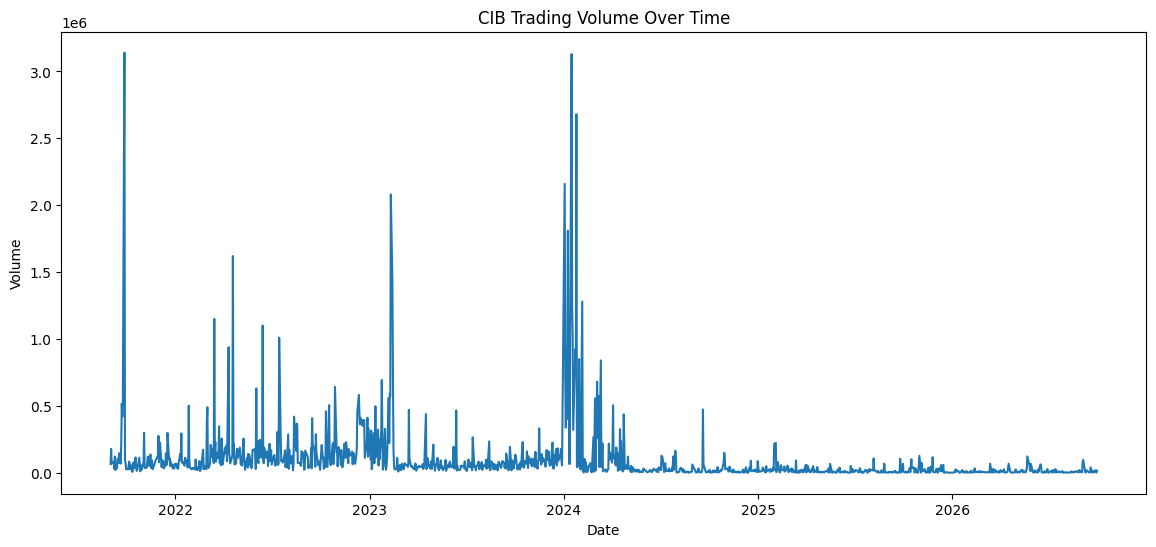

In [25]:
plt.figure(figsize=(14, 6))

plt.plot(df["Date"], df["Volume"])

plt.title("CIB Trading Volume Over Time")
plt.xlabel("Date")
plt.ylabel("Volume")

plt.show()

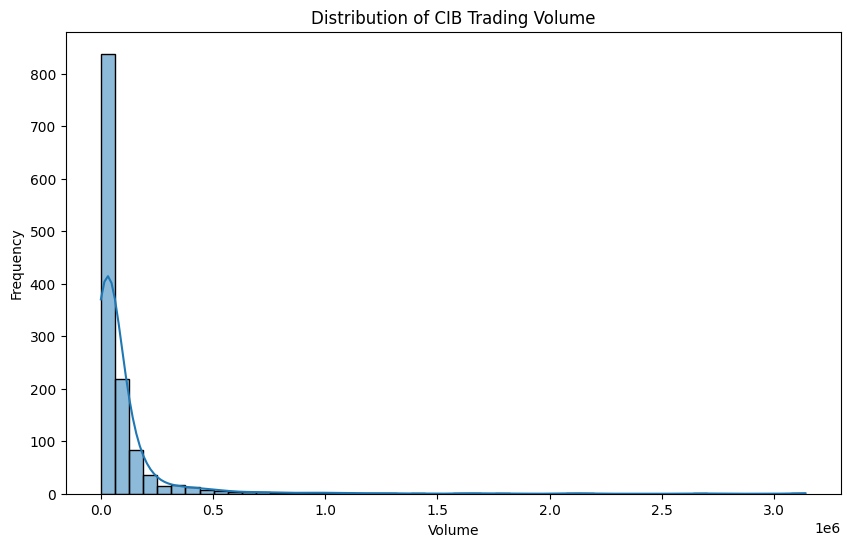

In [26]:
plt.figure(figsize=(10, 6))

sns.histplot(df["Volume"], bins=50, kde=True)

plt.title("Distribution of CIB Trading Volume")
plt.xlabel("Volume")
plt.ylabel("Frequency")

plt.show()

In [27]:
df["Volume"].describe()

count    1.265000e+03
mean     9.375757e+04
std      2.318823e+05
min      1.400000e+02
25%      8.550000e+03
50%      3.355000e+04
75%      8.503000e+04
max      3.140000e+06
Name: Volume, dtype: float64

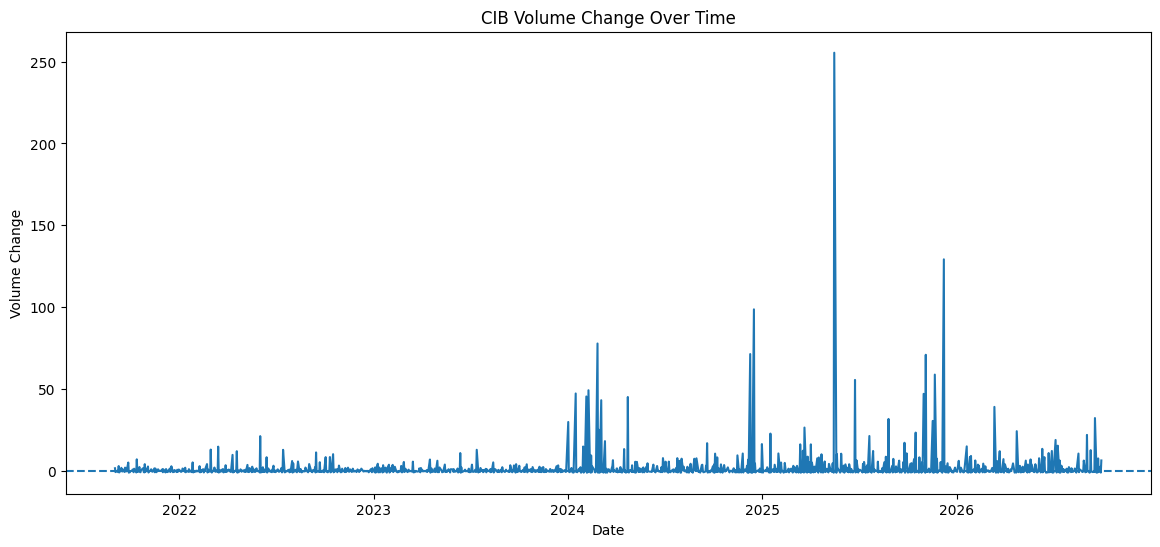

In [28]:
plt.figure(figsize=(14, 6))

plt.plot(df["Date"], df["Volume_Change"])

plt.axhline(0, linestyle="--")

plt.title("CIB Volume Change Over Time")
plt.xlabel("Date")
plt.ylabel("Volume Change")

plt.show()

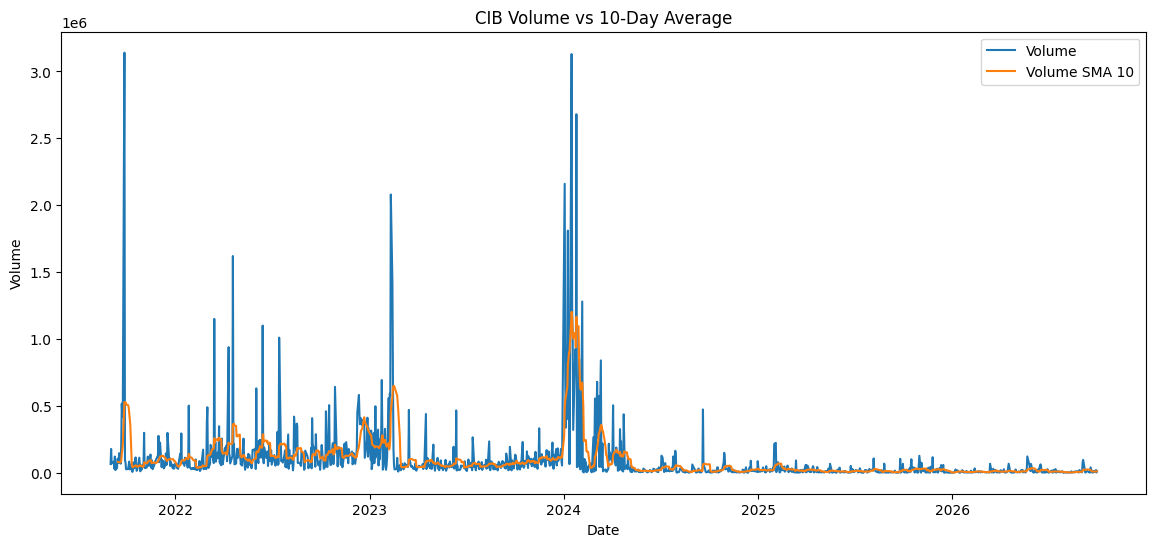

In [29]:
plt.figure(figsize=(14, 6))

plt.plot(df["Date"], df["Volume"], label="Volume")
plt.plot(df["Date"], df["Volume_SMA_10"], label="Volume SMA 10")

plt.title("CIB Volume vs 10-Day Average")
plt.xlabel("Date")
plt.ylabel("Volume")
plt.legend()

plt.show()

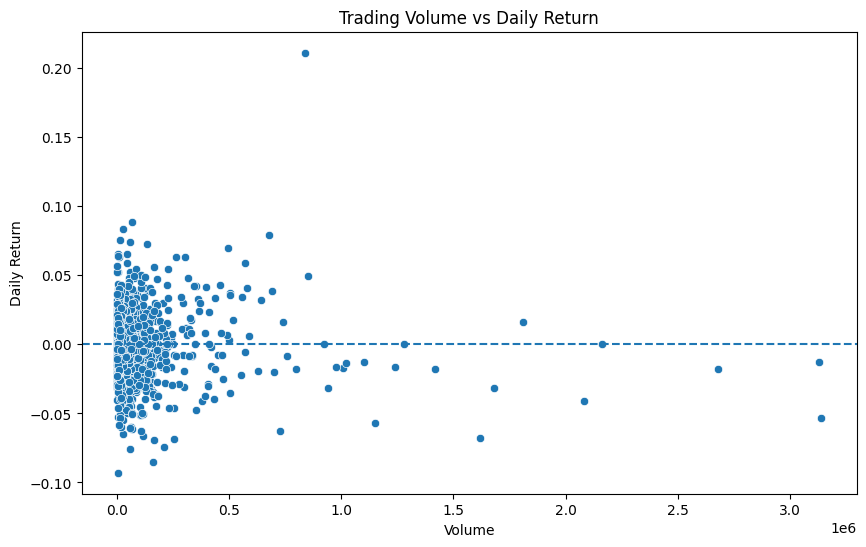

In [30]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Volume",
    y="Return_1d"
)

plt.axhline(0, linestyle="--")

plt.title("Trading Volume vs Daily Return")
plt.xlabel("Volume")
plt.ylabel("Daily Return")

plt.show()

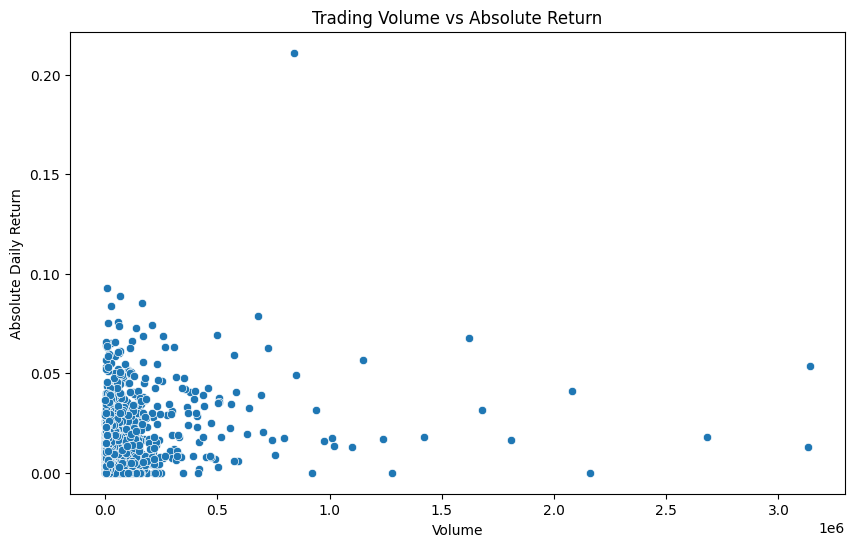

In [31]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Volume",
    y=df["Return_1d"].abs()
)

plt.title("Trading Volume vs Absolute Return")
plt.xlabel("Volume")
plt.ylabel("Absolute Daily Return")

plt.show()

In [32]:
high_volume = df.nlargest(
    10, "Volume"
)[["Date", "Close", "Volume", "Return_1d"]]

display(high_volume)

,Date,Close,Volume,Return_1d
17,2021-09-27,1.682,3140000.0,-0.053461
595,2024-01-16,1.077,3130000.0,-0.012832
602,2024-01-25,0.991,2680000.0,-0.017839
587,2024-01-03,1.109,2160000.0,0.000000
363,2023-02-10,1.500,2080000.0,-0.040921
591,2024-01-09,1.118,1810000.0,0.016364
586,2024-01-02,1.109,1680000.0,-0.031441
158,2022-04-19,1.239,1620000.0,-0.067720
364,2023-02-13,1.473,1420000.0,-0.018000
609,2024-02-05,1.064,1280000.0,0.000000


# 5-Techniqal inticators Analysis

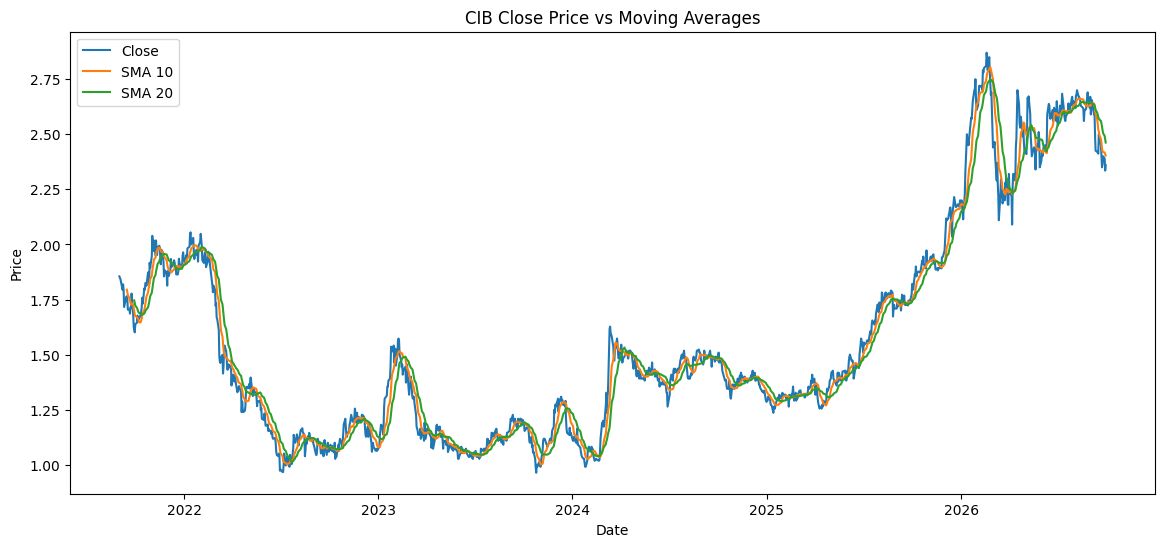

In [33]:
plt.figure(figsize=(14, 6))

plt.plot(df["Date"], df["Close"], label="Close")
plt.plot(df["Date"], df["SMA_10"], label="SMA 10")
plt.plot(df["Date"], df["SMA_20"], label="SMA 20")

plt.title("CIB Close Price vs Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()

plt.show()

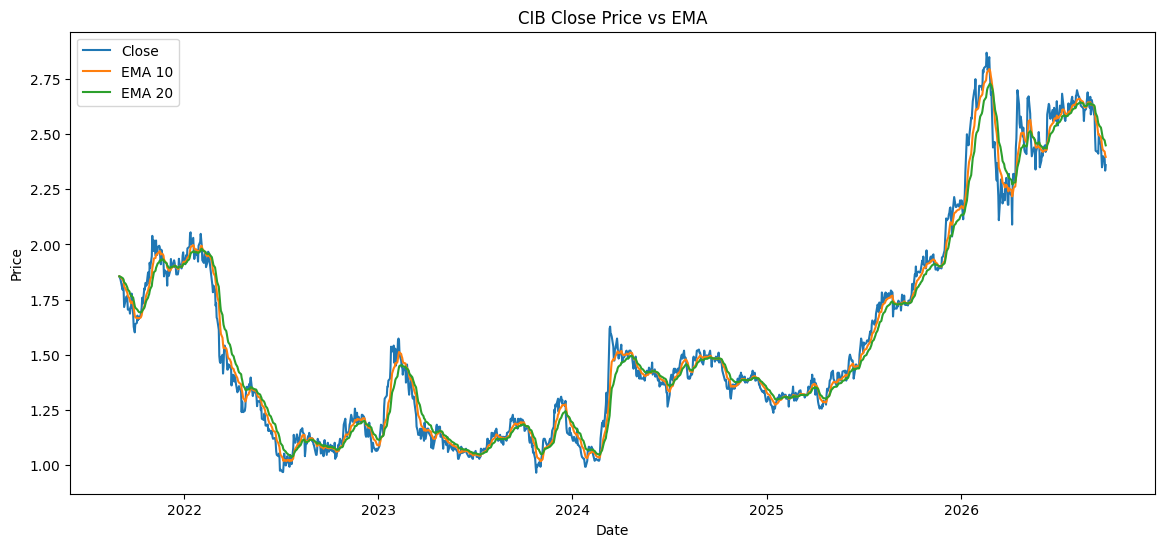

In [34]:
plt.figure(figsize=(14, 6))

plt.plot(df["Date"], df["Close"], label="Close")
plt.plot(df["Date"], df["EMA_10"], label="EMA 10")
plt.plot(df["Date"], df["EMA_20"], label="EMA 20")

plt.title("CIB Close Price vs EMA")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()

plt.show()

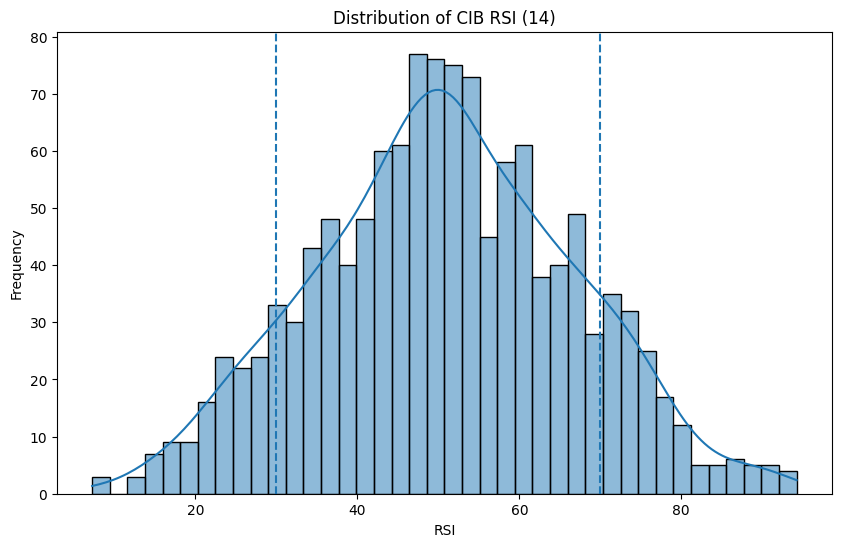

In [35]:
plt.figure(figsize=(10, 6))

sns.histplot(df["RSI_14"].dropna(), bins=40, kde=True)

plt.axvline(30, linestyle="--")
plt.axvline(70, linestyle="--")

plt.title("Distribution of CIB RSI (14)")
plt.xlabel("RSI")
plt.ylabel("Frequency")

plt.show()

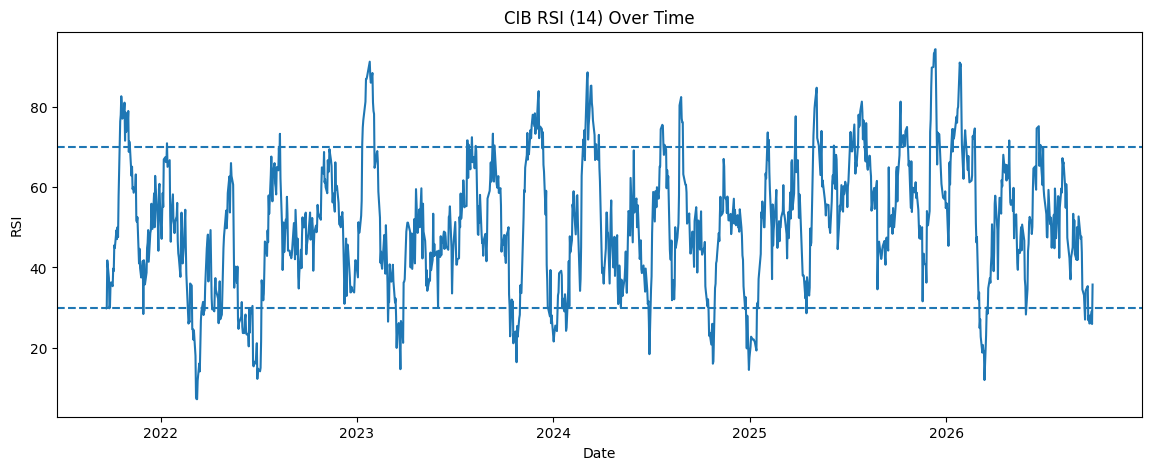

In [36]:
plt.figure(figsize=(14, 5))

plt.plot(df["Date"], df["RSI_14"])

plt.axhline(70, linestyle="--")
plt.axhline(30, linestyle="--")

plt.title("CIB RSI (14) Over Time")
plt.xlabel("Date")
plt.ylabel("RSI")

plt.show()

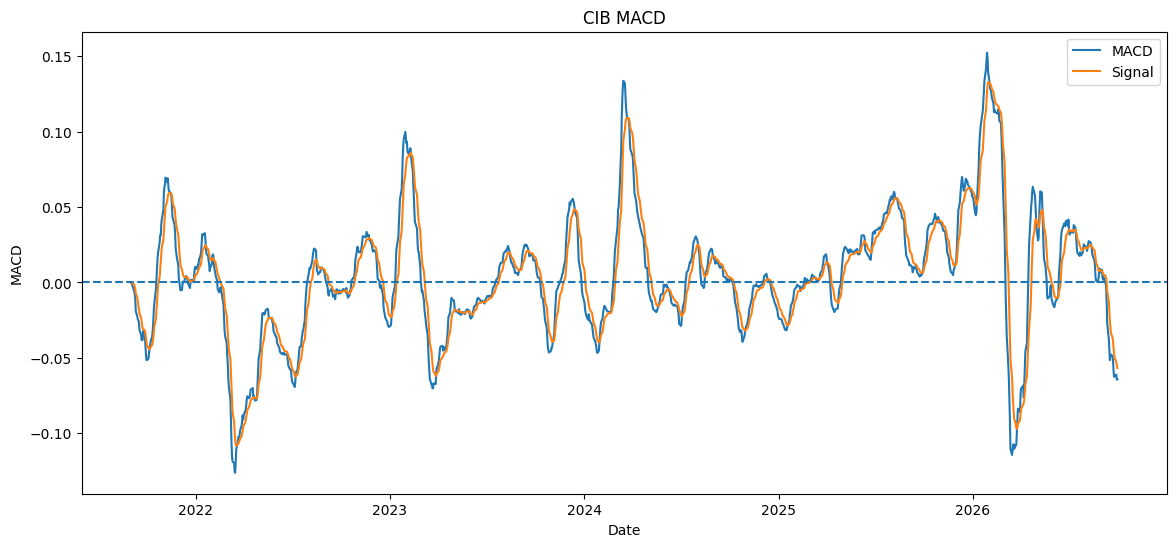

In [37]:
plt.figure(figsize=(14, 6))

plt.plot(df["Date"], df["MACD"], label="MACD")
plt.plot(df["Date"], df["MACD_Signal"], label="Signal")

plt.axhline(0, linestyle="--")

plt.title("CIB MACD")
plt.xlabel("Date")
plt.ylabel("MACD")
plt.legend()

plt.show()

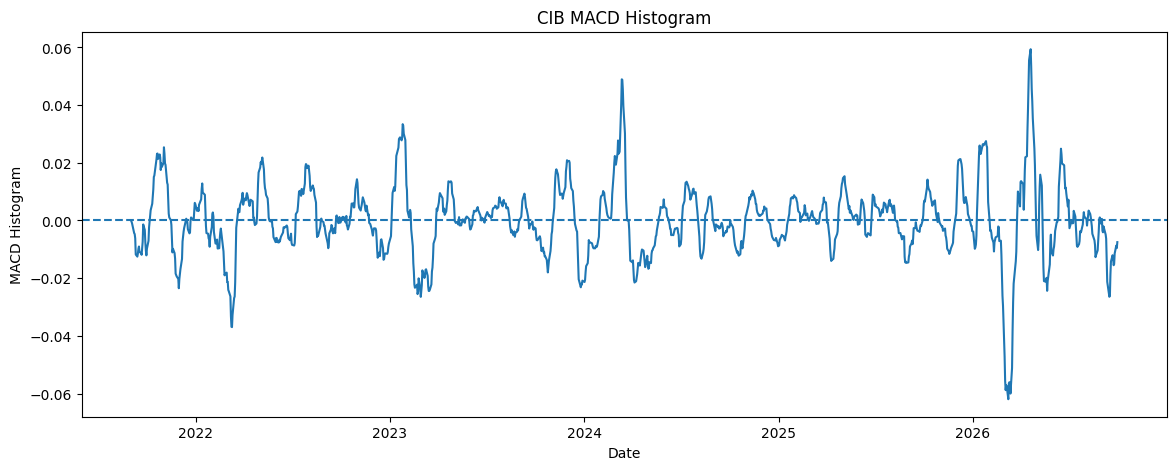

In [38]:
plt.figure(figsize=(14, 5))

plt.plot(df["Date"], df["MACD_Hist"])

plt.axhline(0, linestyle="--")

plt.title("CIB MACD Histogram")
plt.xlabel("Date")
plt.ylabel("MACD Histogram")

plt.show()

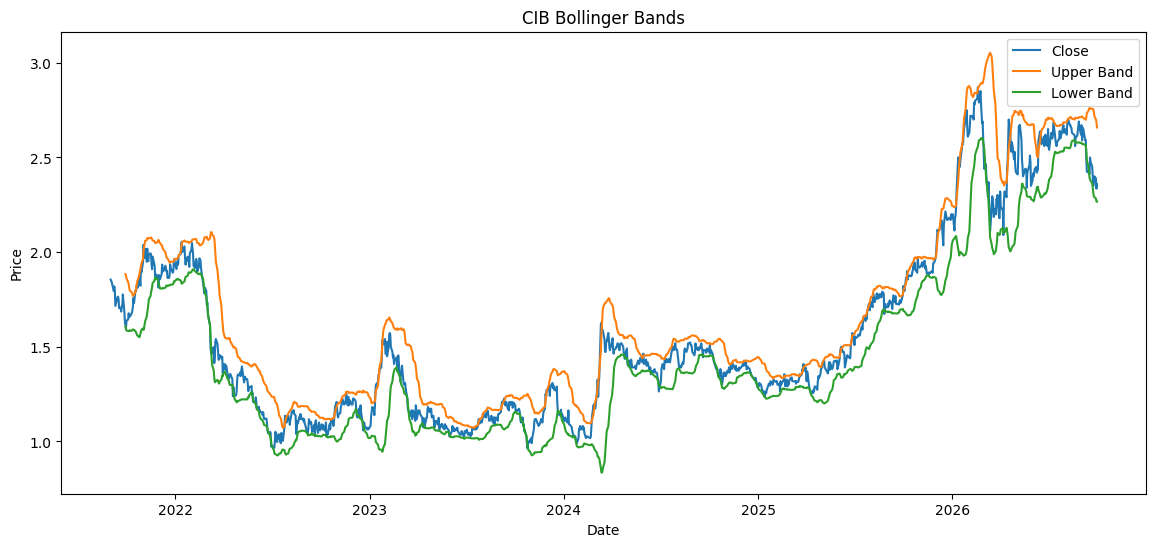

In [39]:
plt.figure(figsize=(14, 6))

plt.plot(df["Date"], df["Close"], label="Close")
plt.plot(df["Date"], df["BB_Upper"], label="Upper Band")
plt.plot(df["Date"], df["BB_Lower"], label="Lower Band")

plt.title("CIB Bollinger Bands")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()

plt.show()

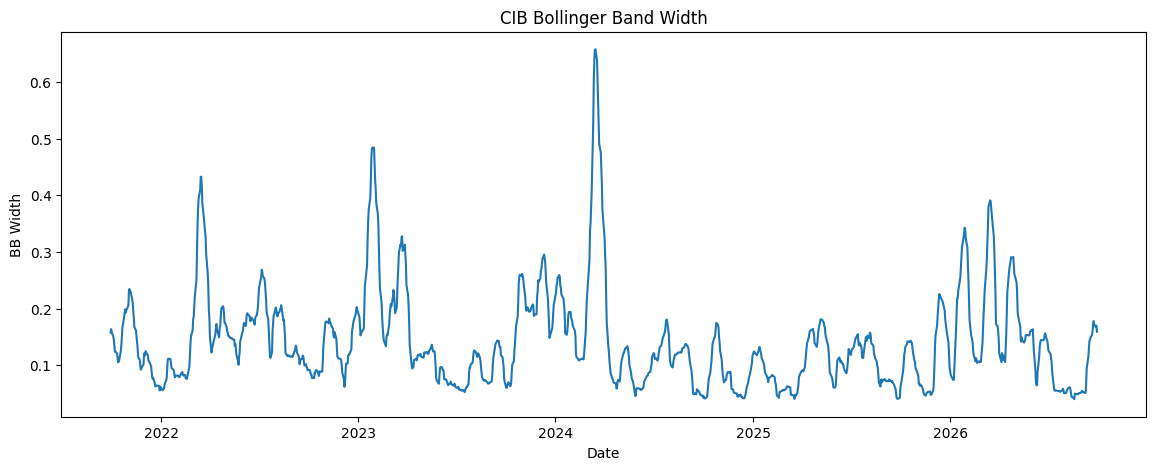

In [40]:
plt.figure(figsize=(14, 5))

plt.plot(df["Date"], df["BB_Width"])

plt.title("CIB Bollinger Band Width")
plt.xlabel("Date")
plt.ylabel("BB Width")

plt.show()

In [41]:
indicator_cols = [
    "SMA_10",
    "SMA_20",
    "EMA_10",
    "EMA_20",
    "RSI_14",
    "MACD",
    "MACD_Signal",
    "MACD_Hist",
    "BB_Width"
]

df[indicator_cols + ["Target"]].corr()["Target"].sort_values()

MACD_Hist     -0.016449
BB_Width      -0.004444
RSI_14         0.222190
MACD           0.354096
MACD_Signal    0.383123
SMA_20         0.978796
EMA_20         0.984136
SMA_10         0.989815
EMA_10         0.991632
Target         1.000000
Name: Target, dtype: float64

# 6. Lag & Autocorrelation Analysis

In [42]:
lag_cols = [
    "Close_lag_1",
    "Close_lag_2",
    "Close_lag_3",
    "Close_lag_5",
    "Close_lag_10"
]

df[lag_cols + ["Target"]].corr()["Target"].sort_values()

Close_lag_10    0.969318
Close_lag_5     0.984699
Close_lag_3     0.989871
Close_lag_2     0.992105
Close_lag_1     0.994453
Target          1.000000
Name: Target, dtype: float64

In [43]:
df["Target_Return"] = (df["Target"] - df["Close"]) / df["Close"]

In [44]:
df[lag_cols + ["Target_Return"]].corr()["Target_Return"].sort_values()

Close_lag_10    -0.030415
Close_lag_5     -0.025502
Close_lag_1     -0.021844
Close_lag_2     -0.019463
Close_lag_3     -0.018296
Target_Return    1.000000
Name: Target_Return, dtype: float64

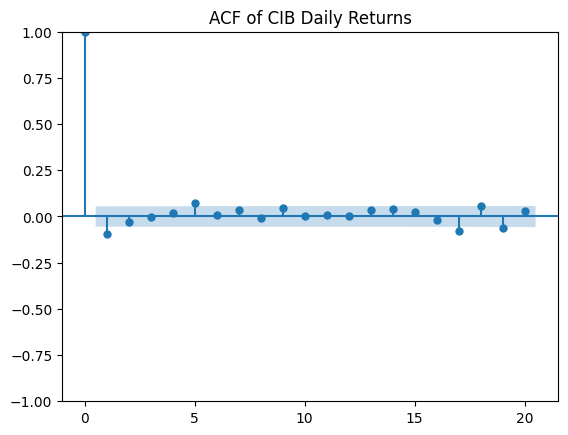

In [45]:
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(
    df["Return_1d"].dropna(),
    lags=20
)

plt.title("ACF of CIB Daily Returns")
plt.show()

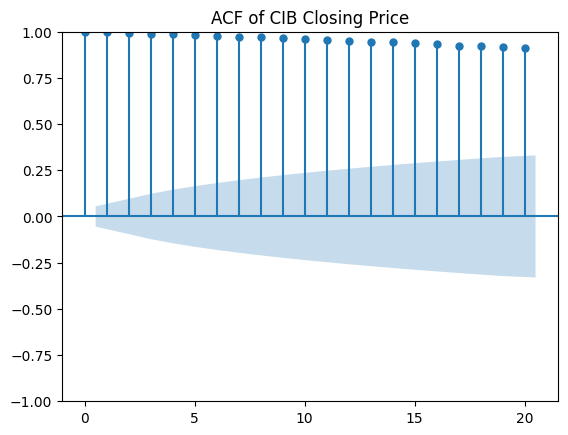

In [46]:
plot_acf(
    df["Close"].dropna(),
    lags=20
)

plt.title("ACF of CIB Closing Price")
plt.show()

# 7-Target Analysis

In [47]:
df["Target"] = df["Close"].shift(-1)

In [48]:
df["Target_Return"] = (df["Target"] - df["Close"]) / df["Close"]

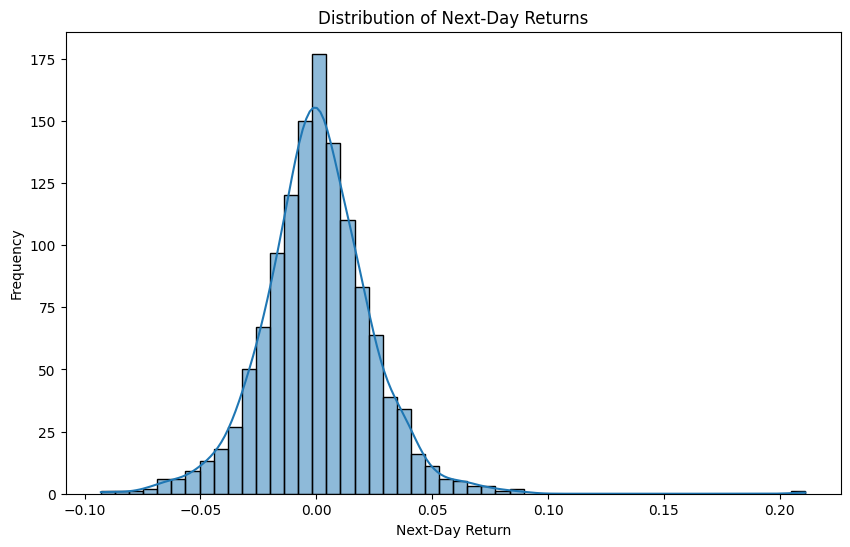

In [49]:
plt.figure(figsize=(10, 6))
sns.histplot(df["Target_Return"].dropna(), bins=50, kde=True)

plt.title("Distribution of Next-Day Returns")
plt.xlabel("Next-Day Return")
plt.ylabel("Frequency")
plt.show()

In [50]:
df["Target_Return"].describe()

count    1264.000000
mean        0.000464
std         0.023489
min        -0.092937
25%        -0.012948
50%         0.000000
75%         0.013662
max         0.211078
Name: Target_Return, dtype: float64

In [51]:
up = (df["Target_Return"] > 0).sum()
down = (df["Target_Return"] < 0).sum()

print("Up:", up)
print("Down:", down)

print("Up %:", up / (up + down) * 100)
print("Down %:", down / (up + down) * 100)

Up: 586
Down: 576
Up %: 50.4302925989673
Down %: 49.5697074010327


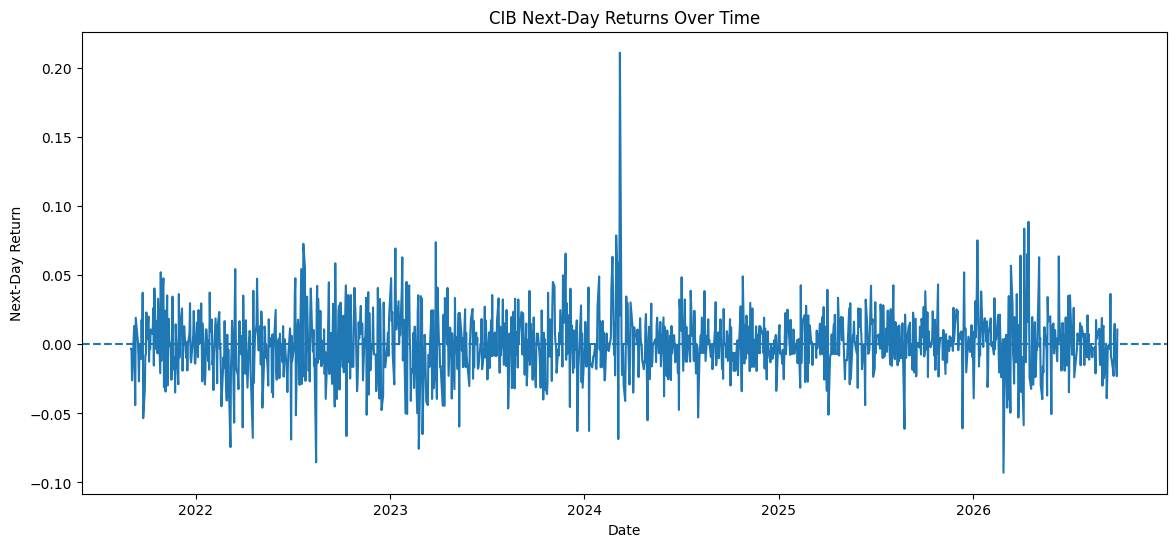

In [53]:
plt.figure(figsize=(14, 6))

plt.plot(df["Date"], df["Target_Return"])
plt.axhline(0, linestyle="--")

plt.title("CIB Next-Day Returns Over Time")
plt.xlabel("Date")
plt.ylabel("Next-Day Return")

plt.show()

# 8- Correlation Analysis

In [54]:
corr_cols = [
    "Close",
    "Open",
    "High",
    "Low",
    "Volume",
    "Return_1d",
    "Return_3d",
    "Return_5d",
    "Return_10d",
    "SMA_10",
    "SMA_20",
    "EMA_10",
    "EMA_20",
    "RSI_14",
    "MACD",
    "MACD_Signal",
    "MACD_Hist",
    "BB_Width",
    "Volatility_10",
    "Volatility_20",
    "High_Low_Range",
    "Open_Close_Range",
    "Volume_Change",
    "Volume_SMA_10",
    "Close_lag_1",
    "Close_lag_2",
    "Close_lag_3",
    "Close_lag_5",
    "Close_lag_10",
    "Target_Return"
]

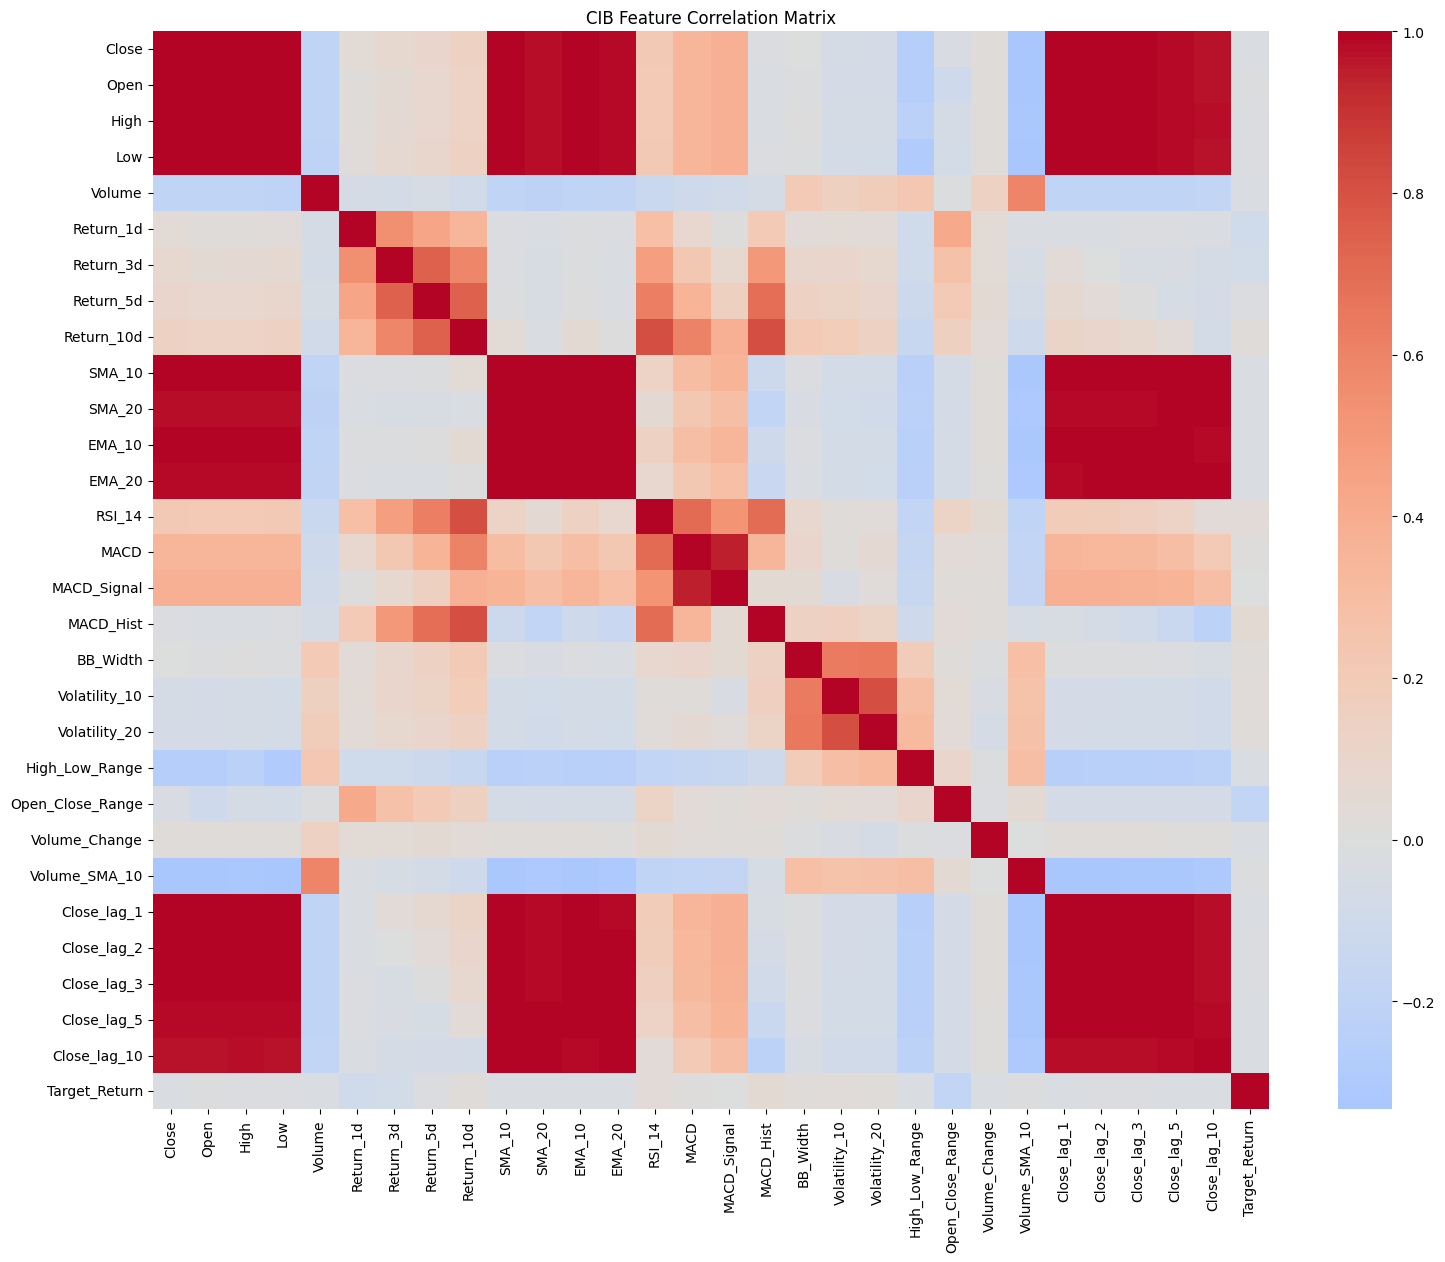

In [56]:
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(18, 14))

sns.heatmap(
    corr_matrix,
    annot=False,
    cmap="coolwarm",
    center=0
)

plt.title("CIB Feature Correlation Matrix")
plt.show()

In [57]:
corr_pairs = (
    corr_matrix
    .where(~np.eye(corr_matrix.shape[0], dtype=bool))
    .stack()
    .reset_index()
)

corr_pairs.columns = ["Feature_1", "Feature_2", "Correlation"]

corr_pairs["Abs_Correlation"] = corr_pairs["Correlation"].abs()

corr_pairs = (
    corr_pairs
    .sort_values("Abs_Correlation", ascending=False)
)

corr_pairs.head(20)

,Feature_1,Feature_2,Correlation,Abs_Correlation
271,SMA_10,EMA_10,0.999647,0.999647
328,EMA_10,SMA_10,0.999647,0.999647
301,SMA_20,EMA_20,0.999075,0.999075
358,EMA_20,SMA_20,0.999075,0.999075
58,High,Close,0.998564,0.998564
1,Close,High,0.998564,0.998564
2,Close,Low,0.998450,0.998450
87,Low,Close,0.998450,0.998450
88,Low,Open,0.998253,0.998253
31,Open,Low,0.998253,0.998253


# 9- Time / Seasonality Analysis

In [58]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Day_of_Week"] = df["Date"].dt.day_name()

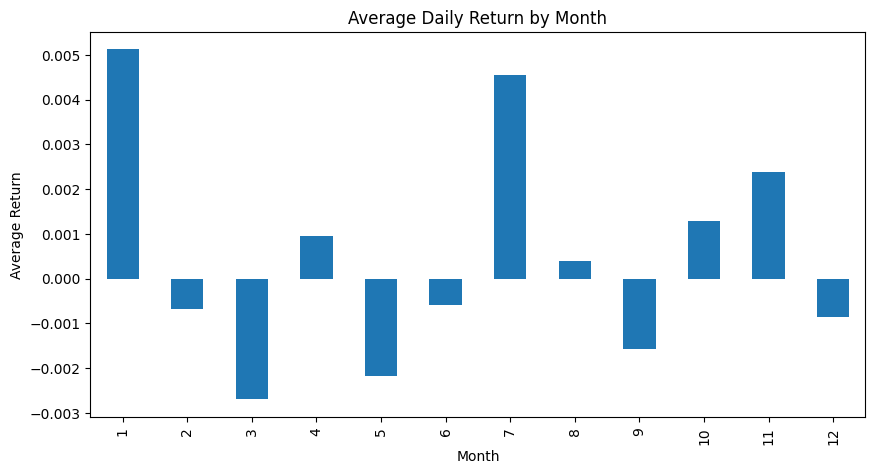

In [59]:
monthly_return = (
    df.groupby("Month")["Return_1d"]
    .mean()
)

plt.figure(figsize=(10, 5))

monthly_return.plot(kind="bar")

plt.title("Average Daily Return by Month")
plt.xlabel("Month")
plt.ylabel("Average Return")

plt.show()

In [60]:
monthly_direction = (
    df.assign(
        Direction=df["Return_1d"].apply(
            lambda x: "Up" if x > 0 else "Down"
        )
    )
    .groupby(["Month", "Direction"])
    .size()
    .unstack(fill_value=0)
)

monthly_direction["Up_%"] = (
    monthly_direction["Up"] /
    monthly_direction.sum(axis=1) * 100
)

monthly_direction["Down_%"] = (
    monthly_direction["Down"] /
    monthly_direction.sum(axis=1) * 100
)

monthly_direction

Direction,Down,Up,Up_%,Down_%
Month,,,,
1,47,54,53.465347,30.427537
2,52,44,45.833333,36.662750
3,66,43,39.449541,44.459551
4,54,48,47.058824,36.227309
5,55,48,46.601942,36.764229
6,55,47,46.078431,37.142479
7,50,56,52.830189,31.480162
8,58,50,46.296296,37.590014
9,74,50,40.322581,45.033373


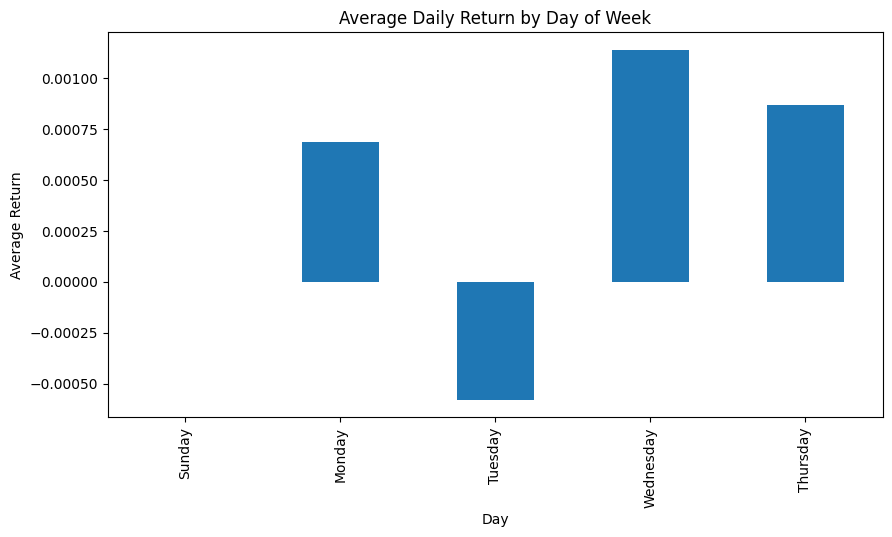

In [61]:
weekday_return = (
    df.groupby("Day_of_Week")["Return_1d"]
    .mean()
)

weekday_order = [
    "Sunday",
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday"
]

weekday_return = weekday_return.reindex(weekday_order)

plt.figure(figsize=(10, 5))

weekday_return.plot(kind="bar")

plt.title("Average Daily Return by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average Return")

plt.show()

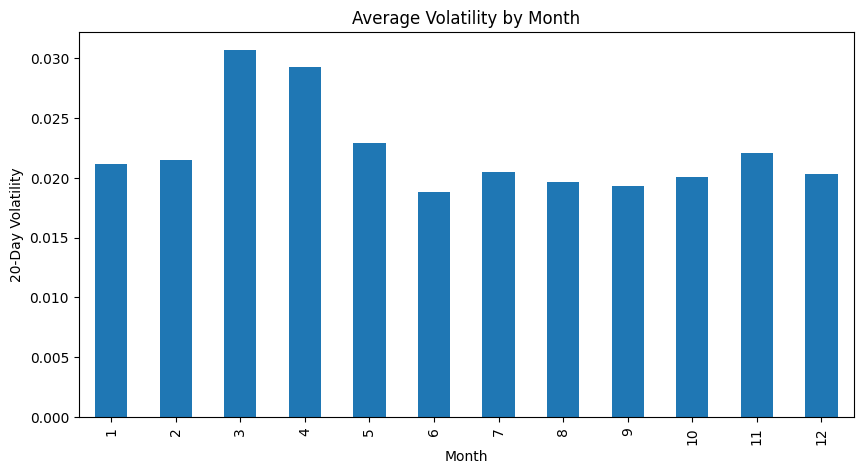

In [62]:
monthly_volatility = (
    df.groupby("Month")["Volatility_20"]
    .mean()
)

plt.figure(figsize=(10, 5))

monthly_volatility.plot(kind="bar")

plt.title("Average Volatility by Month")
plt.xlabel("Month")
plt.ylabel("20-Day Volatility")

plt.show()

# 10 - Market Regimes

In [63]:
df["Volatility_Regime"] = pd.qcut(
    df["Volatility_20"],
    q=3,
    labels=["Low", "Medium", "High"]
)

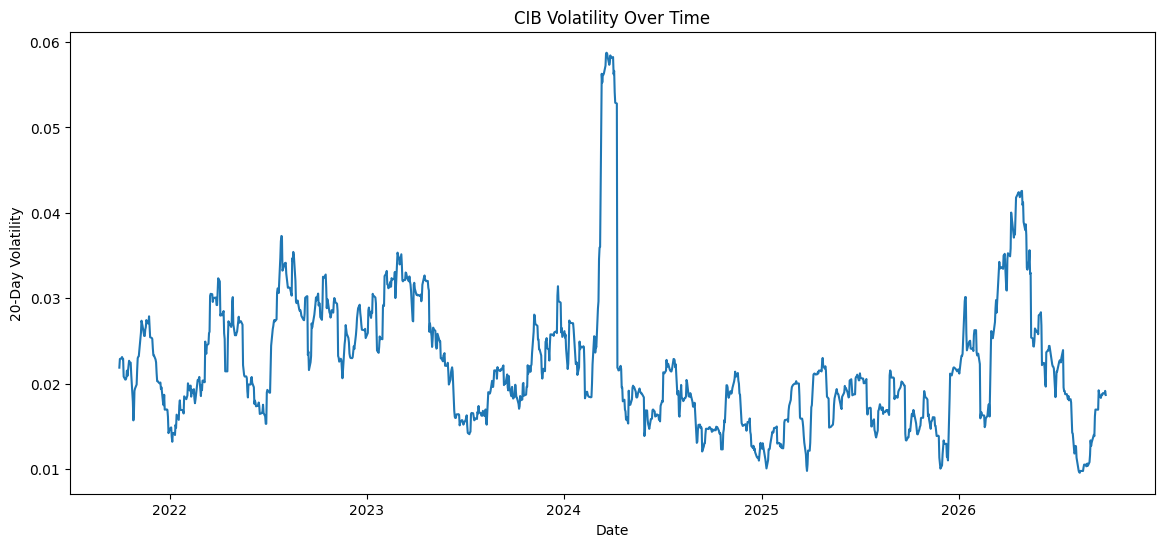

In [64]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["Volatility_20"]
)

plt.title("CIB Volatility Over Time")
plt.xlabel("Date")
plt.ylabel("20-Day Volatility")

plt.show()

In [65]:
regime_stats = (
    df.groupby("Volatility_Regime", observed=True)
    .agg(
        Avg_Return=("Return_1d", "mean"),
        Avg_Target_Return=("Target_Return", "mean"),
        Avg_Volatility=("Volatility_20", "mean"),
        Observations=("Return_1d", "count")
    )
)

regime_stats

,Avg_Return,Avg_Target_Return,Avg_Volatility,Observations
Volatility_Regime,,,,
Low,-0.000083,-0.001109,0.015218,415
Medium,0.001159,0.002127,0.020762,415
High,0.000662,0.000743,0.030640,415


In [66]:
df["Rolling_Return_20"] = df["Close"].pct_change(20)

In [67]:
df["Trend_Regime"] = pd.cut(
    df["Rolling_Return_20"],
    bins=[-float("inf"), -0.05, 0.05, float("inf")],
    labels=["Bearish", "Sideways", "Bullish"]
)

In [68]:
trend_stats = (
    df.groupby("Trend_Regime", observed=True)
    .agg(
        Avg_Return=("Return_1d", "mean"),
        Avg_Target_Return=("Target_Return", "mean"),
        Avg_Volatility=("Volatility_20", "mean"),
        Observations=("Return_1d", "count")
    )
)

trend_stats

,Avg_Return,Avg_Target_Return,Avg_Volatility,Observations
Trend_Regime,,,,
Bearish,-0.006403,0.000053,0.023649,310
Sideways,0.000756,0.000359,0.019821,557
Bullish,0.006045,0.001356,0.024539,378


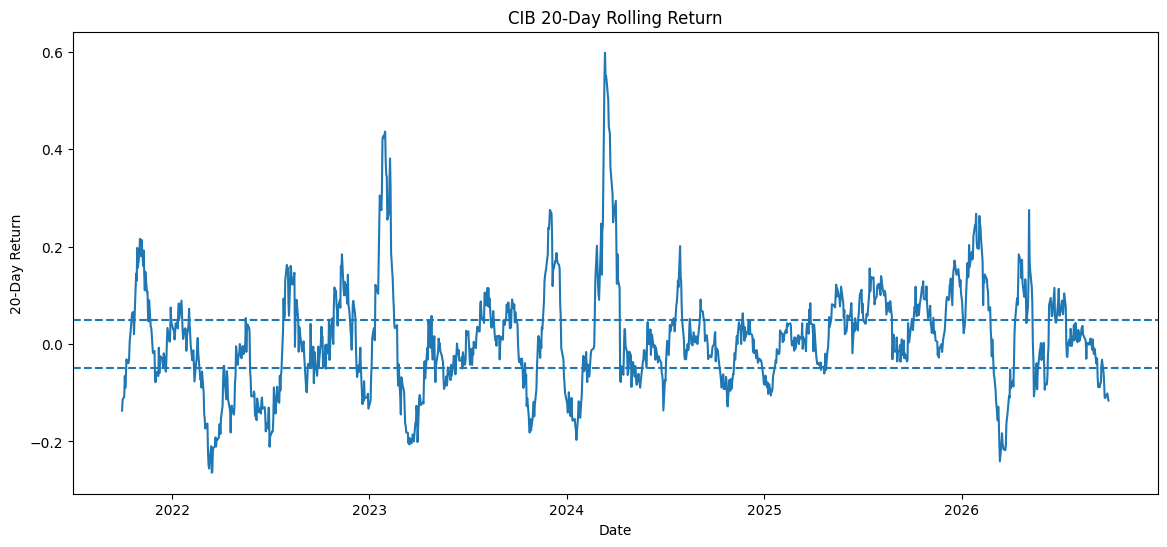

In [69]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["Rolling_Return_20"]
)

plt.axhline(0.05, linestyle="--")
plt.axhline(-0.05, linestyle="--")

plt.title("CIB 20-Day Rolling Return")
plt.xlabel("Date")
plt.ylabel("20-Day Return")

plt.show()

# 11-Outliers

In [70]:
best_days = df.nlargest(
    10, "Return_1d"
)[["Date", "Close", "Return_1d"]]

worst_days = df.nsmallest(
    10, "Return_1d"
)[["Date", "Close", "Return_1d"]]

print("Best 10 Days")
display(best_days)

print("Worst 10 Days")
display(worst_days)

Best 10 Days


,Date,Close,Return_1d
633,2024-03-11,1.618,0.211078
1151,2026-04-17,2.700,0.088710
1145,2026-04-08,2.265,0.083732
628,2024-03-04,1.273,0.078814
1086,2026-01-12,2.500,0.075269
395,2023-03-29,1.191,0.073940
224,2022-07-25,1.076,0.072782
343,2023-01-12,1.264,0.069374
563,2023-11-28,1.250,0.065644
1149,2026-04-14,2.440,0.065502


Worst 10 Days


,Date,Close,Return_1d
1119,2026-03-02,2.440,-0.092937
240,2022-08-16,1.039,-0.085387
373,2023-02-27,1.345,-0.075601
129,2022-03-08,1.493,-0.074396
208,2022-06-30,0.973,-0.068900
630,2024-03-06,1.236,-0.068576
158,2022-04-19,1.239,-0.067720
280,2022-10-12,1.027,-0.066364
378,2023-03-06,1.309,-0.065000
579,2023-12-20,1.209,-0.062791


In [71]:
Q1 = df["Return_1d"].quantile(0.25)
Q3 = df["Return_1d"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

return_outliers = df[
    (df["Return_1d"] < lower_bound) |
    (df["Return_1d"] > upper_bound)
]

print("Number of return outliers:", len(return_outliers))
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Number of return outliers: 42
Lower bound: -0.052861999758353644
Upper bound: 0.05357575269990787


In [72]:
volume_threshold = df["Volume"].quantile(0.99)

volume_spikes = df[
    df["Volume"] > volume_threshold
][["Date", "Close", "Volume", "Return_1d"]]

print("Volume spike threshold:", volume_threshold)

display(
    volume_spikes.sort_values(
        "Volume",
        ascending=False
    ).head(10)
)

Volume spike threshold: 1048799.999999992


,Date,Close,Volume,Return_1d
17,2021-09-27,1.682,3140000.0,-0.053461
595,2024-01-16,1.077,3130000.0,-0.012832
602,2024-01-25,0.991,2680000.0,-0.017839
587,2024-01-03,1.109,2160000.0,0.000000
363,2023-02-10,1.500,2080000.0,-0.040921
591,2024-01-09,1.118,1810000.0,0.016364
586,2024-01-02,1.109,1680000.0,-0.031441
158,2022-04-19,1.239,1620000.0,-0.067720
364,2023-02-13,1.473,1420000.0,-0.018000
609,2024-02-05,1.064,1280000.0,0.000000


In [73]:
vol_threshold = df["Volatility_20"].quantile(0.95)

high_vol_periods = df[
    df["Volatility_20"] > vol_threshold
][["Date", "Close", "Return_1d", "Volatility_20"]]

print("High volatility threshold:", vol_threshold)

display(
    high_vol_periods.sort_values(
        "Volatility_20",
        ascending=False
    ).head(10)
)

High volatility threshold: 0.03453138012101041


,Date,Close,Return_1d,Volatility_20
640,2024-03-20,1.473,0.000000,0.058738
639,2024-03-19,1.473,-0.041016,0.058661
641,2024-03-21,1.524,0.034623,0.058652
645,2024-03-27,1.500,-0.029126,0.058419
642,2024-03-22,1.527,0.001969,0.058245
647,2024-04-01,1.527,0.030364,0.058228
646,2024-03-28,1.482,-0.012000,0.058133
644,2024-03-26,1.545,-0.017800,0.057583
643,2024-03-25,1.573,0.030124,0.057322
638,2024-03-18,1.536,-0.029077,0.057216


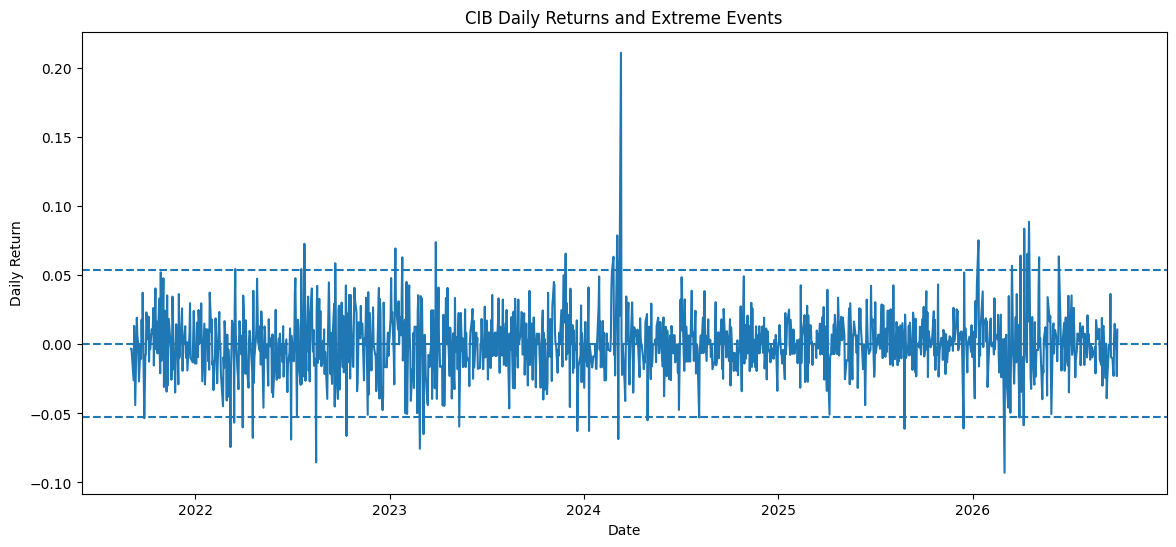

In [74]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["Return_1d"]
)

plt.axhline(
    upper_bound,
    linestyle="--"
)

plt.axhline(
    lower_bound,
    linestyle="--"
)

plt.axhline(0, linestyle="--")

plt.title("CIB Daily Returns and Extreme Events")
plt.xlabel("Date")
plt.ylabel("Daily Return")

plt.show()